# Dannyl MOUHEB – Modèle churn ClientCo – 2. Quelles features comptent ?

À lancer **après le notebook 1** (réutilise ses photos : `cache/photos_mensuelles.pkl`).

**La matrice produite** : une ligne par feature, une colonne par indicateur.
| Indicateur | Lecture |
|---|---|
| `permutation_ca_capte` | points de CA à risque capté perdus si on mélange la feature (indicateur métier) |
| `permutation_pr_auc` | perte de PR-AUC si on mélange la feature |
| `gain_xgboost` | part du gain apportée dans les arbres XGBoost |
| `auc_seule` | AUC avec cette feature seule (0,5 = inutile seule) |
| `moyenne_churners` / `moyenne_restants` / `ratio` | profil des clients qui partent vs qui restent |
| `permutation_total` / `permutation_partiel` | importance pour le départ total vs la forte baisse |
| `rang_moyen` | rang moyen sur les 4 premiers indicateurs (1 = la plus importante) |

In [1]:
# --- Mise en place (ne pas modifier) -------------------------------------------------------------
# Le notebook se place à la racine du dépôt (où se trouve data/) et rend importables les modules
# du dossier dannyl_modele_churn.
import os, sys, json
import pandas as pd
from IPython.display import Image, display
if os.path.basename(os.getcwd()) == "dannyl_modele_churn":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("dannyl_modele_churn"))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RES = os.path.join("dannyl_modele_churn", "resultats")
print("Dossier de travail :", os.getcwd())

Dossier de travail : c:\Users\DanXVI\Desktop\CentraleSupélec\3A\M2AD\EDC 3\case_BCGX


In [2]:
import importlib, dannyl_2_importance_variables as script
importlib.reload(script)
sys.argv = ["dannyl_2_importance_variables"] + []
script.main()

Modèle analysé : Gradient boosting (XGBoost) (cible : départ total ou forte baisse)
Permutations (CA capté)...
Permutations (PR-AUC)...
Permutations (churn_total)...
Permutations (churn_partiel)...

== Top 10 (rang moyen) ==
               permutation_ca_capte  permutation_pr_auc  gain_xgboost  auc_seule  rang_moyen
ca_1m                        0.0678              0.0233        0.0441     0.6927        3.25
jours_3m                     0.0151              0.0125        0.2030     0.7051        3.25
jours_1m                     0.0318              0.0093        0.3369     0.6988        3.25
indice_saison                0.0512              0.0777        0.0600     0.6102        5.25
recence_j                    0.0074              0.0079        0.0655     0.6890        6.25
produits_3m                  0.0084              0.0038        0.0321     0.6954        7.50
tendance_6m                  0.0181              0.0093        0.0275     0.6032        8.75
jours_12m                    0.

## Matrice d'importance

In [3]:
M = pd.read_csv(os.path.join(RES, "importance", "matrice_importance.csv"), sep=";", index_col=0)
display(M)

,description,permutation_ca_capte,permutation_pr_auc,gain_xgboost,auc_seule,moyenne_churners,moyenne_restants,ratio_churners_restants,permutation_total,permutation_partiel,rang_moyen
feature,,,,,,,,,,,
ca_1m,CA net des 30 derniers jours,0.0678,0.0233,0.0441,0.6927,1.244609e+03,5.260021e+03,0.2366,0.0033,0.0096,3.25
jours_3m,nombre de jours d'achat sur 91 jours,0.0151,0.0125,0.2030,0.7051,4.834700e+00,1.229860e+01,0.3931,0.0300,0.0020,3.25
jours_1m,nombre de jours d'achat sur 30 jours,0.0318,0.0093,0.3369,0.6988,1.414300e+00,3.995300e+00,0.3540,0.0085,0.0038,3.25
indice_saison,CA du même trimestre N-1 / CA trimestriel moye...,0.0512,0.0777,0.0600,0.6102,1.035500e+00,6.760000e-01,1.5317,0.0004,0.0956,5.25
recence_j,jours depuis le dernier jour d'achat,0.0074,0.0079,0.0655,0.6890,3.797800e+01,1.966470e+01,1.9313,0.0286,0.0042,6.25
produits_3m,somme des produits différents achetés par mois...,0.0084,0.0038,0.0321,0.6954,2.357890e+01,8.446680e+01,0.2791,0.0245,0.0051,7.50
tendance_6m,CA des 182 derniers jours / CA des 182 jours p...,0.0181,0.0093,0.0275,0.6032,2.083500e+00,2.525400e+00,0.8250,0.0003,0.0152,8.75
jours_12m,nombre de jours d'achat sur 365 jours,0.0015,0.0134,0.0158,0.6627,2.262750e+01,4.753540e+01,0.4760,0.0153,0.0033,10.00
recence_ratio,silence actuel / délai médian habituel (> 1 = ...,0.0045,0.0075,0.0253,0.5581,3.065300e+00,1.953200e+00,1.5694,0.0143,0.0009,11.25


## Visualisations

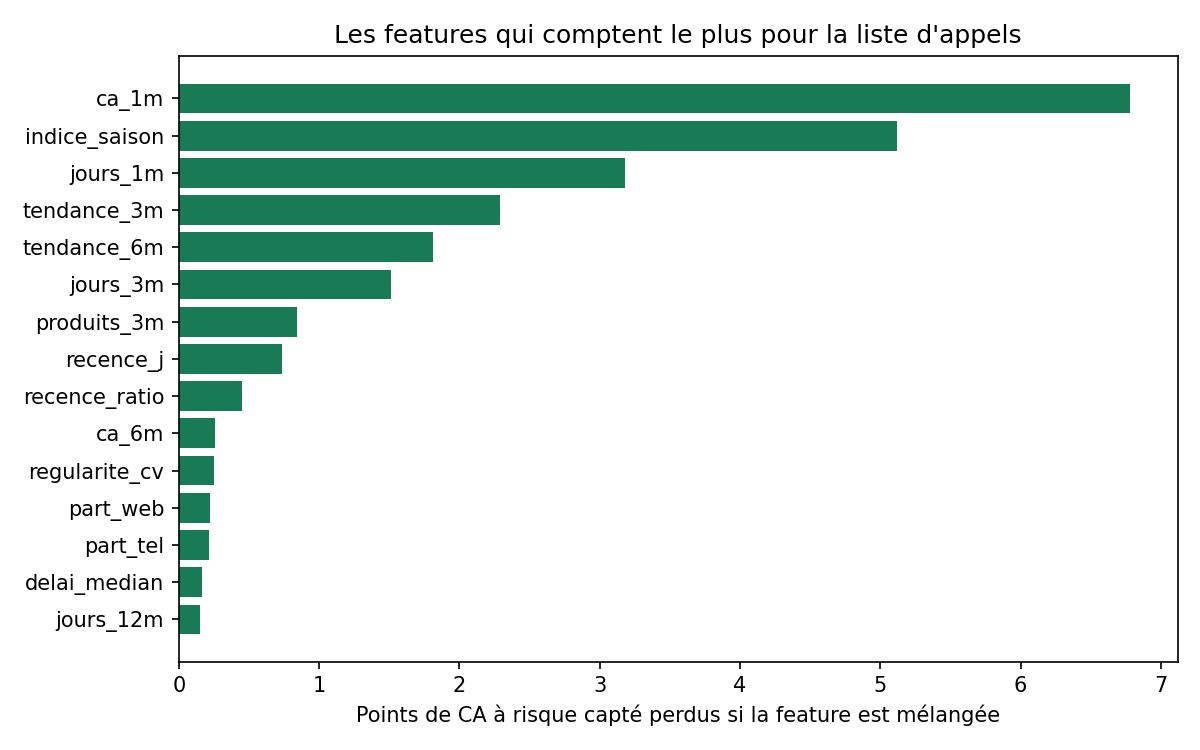

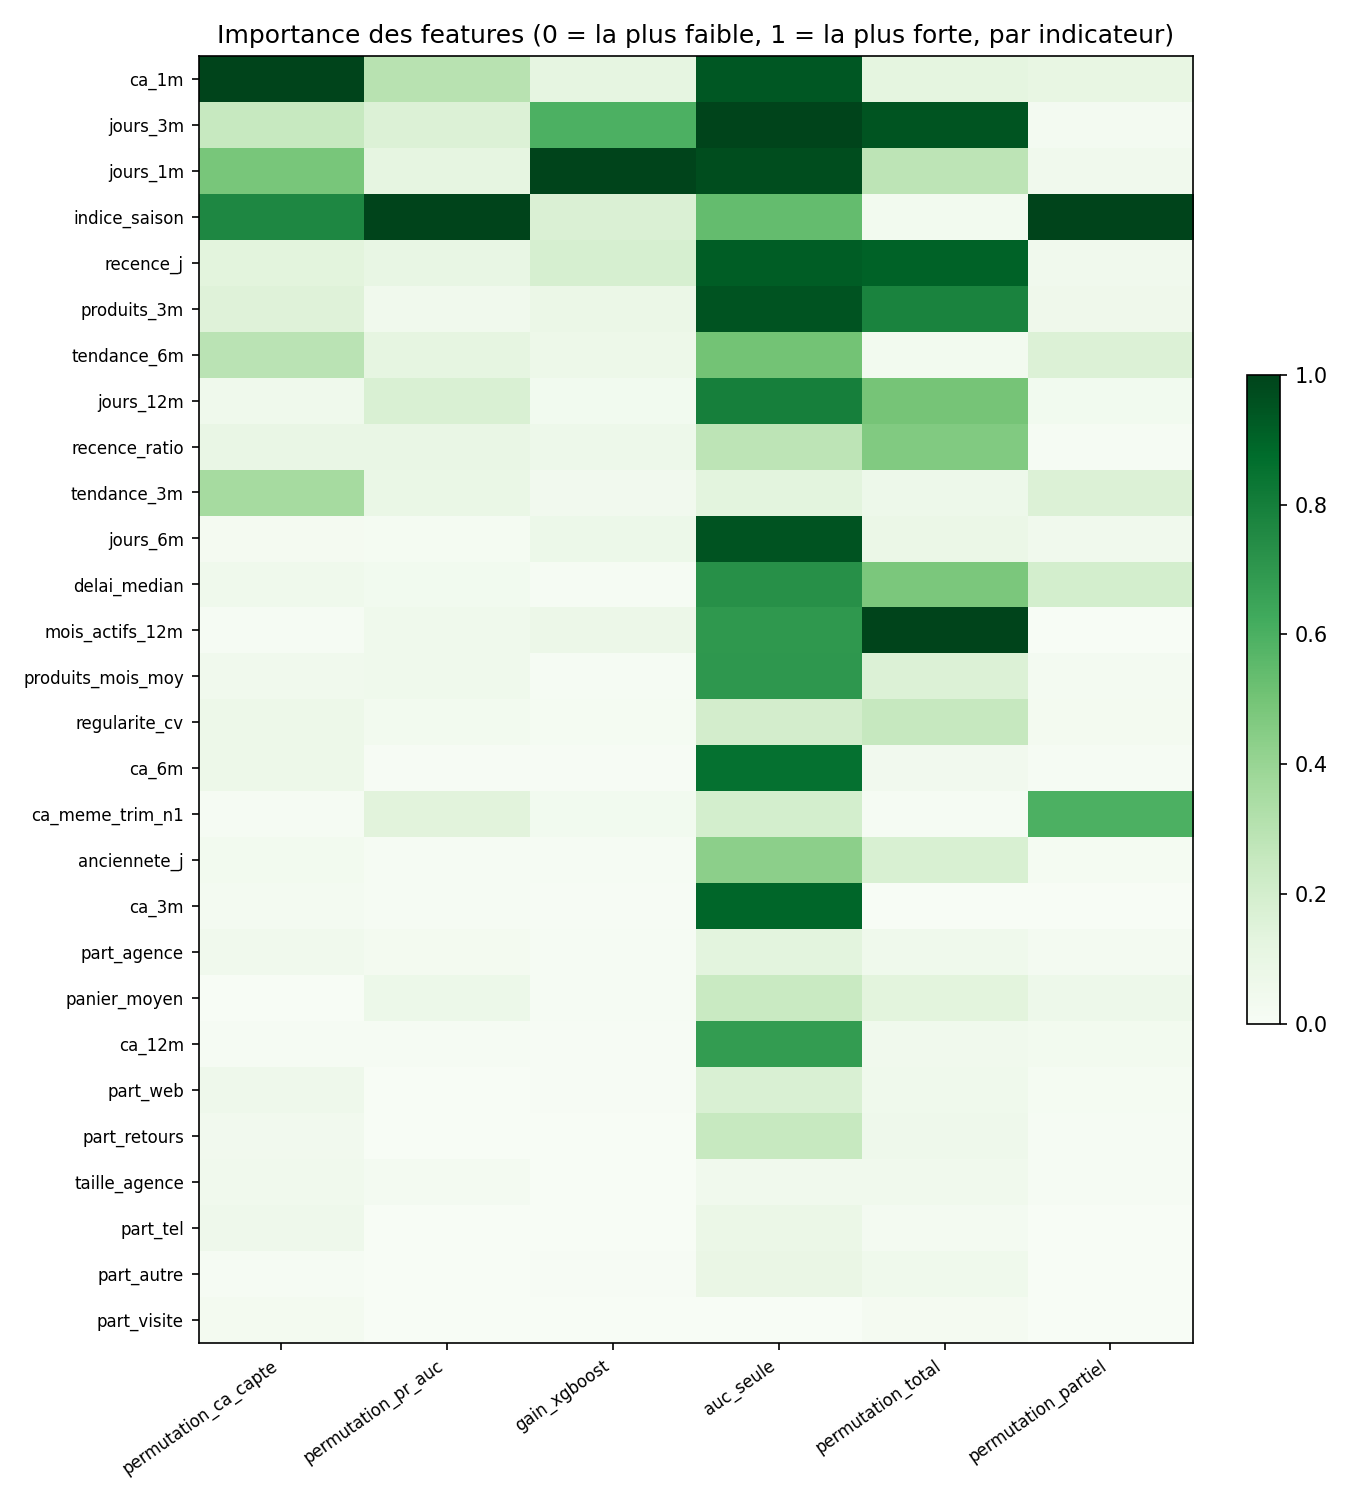

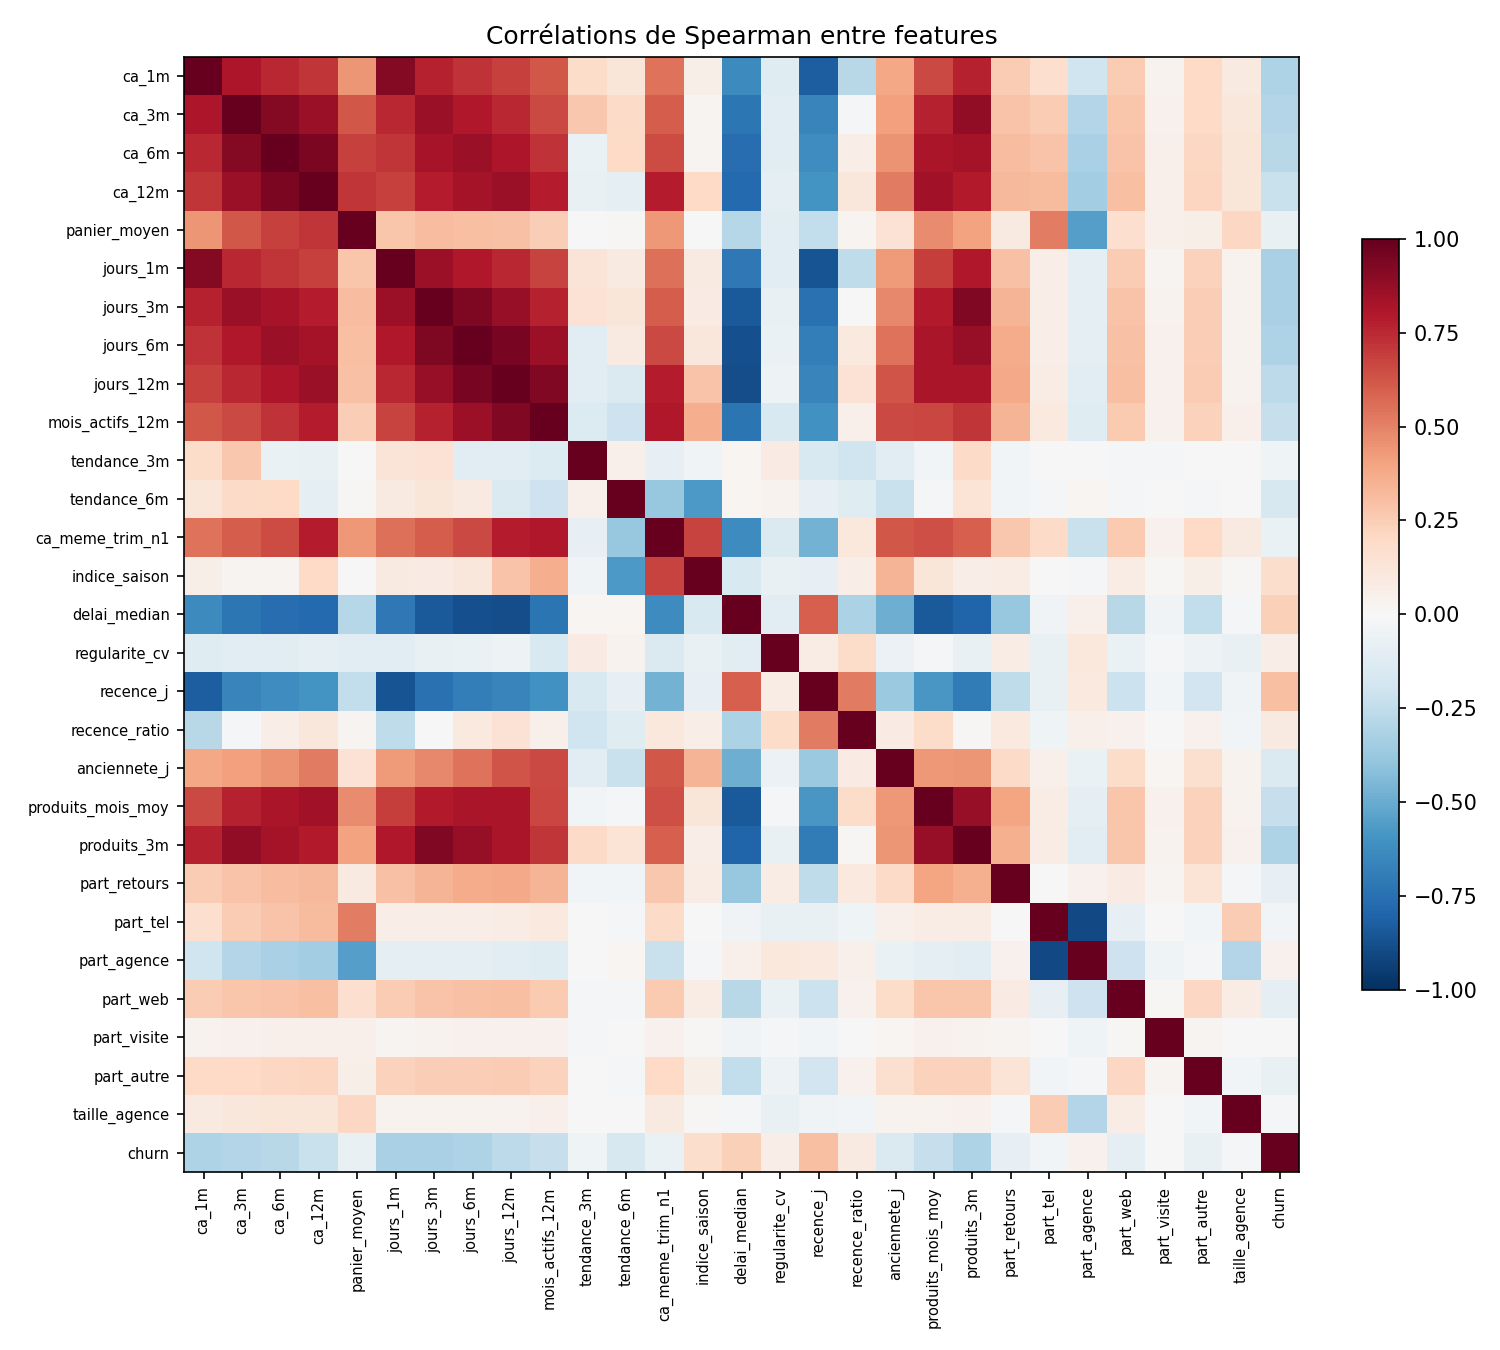

In [4]:
for f in ("top_variables.png", "matrice_importance.png", "correlations.png"):
    display(Image(os.path.join(RES, "importance", f)))

## Features quasi redondantes (|corrélation de Spearman| > 0,9)

In [5]:
corr = pd.read_csv(os.path.join(RES, "importance", "correlations.csv"), sep=";", index_col=0)
paires = [(i, j, round(corr.loc[i, j], 2)) for k, i in enumerate(corr.index) for j in corr.columns[k + 1:] if abs(corr.loc[i, j]) > 0.9]
display(pd.DataFrame(paires, columns=["feature_1", "feature_2", "correlation"]))

,feature_1,feature_2,correlation
0,ca_1m,jours_1m,0.92
1,ca_3m,ca_6m,0.92
2,ca_6m,ca_12m,0.94
3,jours_3m,jours_6m,0.93
4,jours_3m,produits_3m,0.93
5,jours_6m,jours_12m,0.95
6,jours_12m,mois_actifs_12m,0.93
7,part_tel,part_agence,-0.90
